# Bonnet Carré Spillway: Leakage & Discharge Quantification

This notebook estimates flow through the Bonnet Carré Spillway (BCS) on the lower Mississippi River, combining two regimes:

1. **Non-operational leakage**: when the spillway is *closed*, river water still seeps through the ~0.5" gaps between the timber "needles" filling each bay. This is modeled with a broad-crested weir / slot-flow equation from the gauge-recorded river stage.
2. **Operational discharge**: when the spillway is *opened*, the USACE records the actual diverted flow. Those recorded values are used directly and always take precedence over the leakage model.

**Inputs (in `data/external/`):**
- `waterlevel_BCS_USACE.txt`: daily river stage at USACE gauge 01280 (tab-separated: `date`, `waterlevel` in feet on the gauge's local datum). Download: https://rivergages.mvr.usace.army.mil/WaterControl/stationinfo2.cfm?sid=01280&fid=NORL1&dt=S&pcode=HG
- `Bonnet_Carre_ALL_Weeks_USACE.XLSX`: recorded operational diversion discharge (m³/s), one column per historical opening event.

**Output (place in `outputs/bcs/`):** `bcs_leakage_discharge_2000_present.csv`: leakage and combined discharge by date, 2000 to the end of record (as of now, June 2026 CRRT).

**How to reproduce for a new time range or updated data:** drop refreshed files into `data/external/`, then Run All. 
- For updating leakage, add the updated water level data from the USACE gauge to the bottom of `waterlevel_BCS_USACE.txt`. 
- If an opening occured, add a column in `Bonnet_Carre_ALL_Weeks_USACE.XLSX` and line it up with the month and day (ignore year).


## 1. Upload Packages

In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from datetime import datetime
from pathlib import Path
import sys


# Resolve project root regardless of whether CWD is repository root or notebooks/
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))


data_file = PROJECT_ROOT / "data" / "external" / "waterlevel_BCS_USACE.txt"
bcs_wl = pd.read_csv(data_file, sep='\t', header=0)

## 2. Gauge Datum Offset

USACE gauge 01280 reports river **stage** on its own local staff-gauge zero.
That datum is **not** the same as the weir sill datum used by the leakage model
(sill elevations at 15 ft and 17 ft).

To compute head above the sill correctly, convert gauge readings to the sill datum:

&nbsp;&nbsp;&nbsp;&nbsp; **water_level_on_sill_datum_ft = raw_gauge_ft - datum_ft**

Where:
- **water_level_on_sill_datum_ft**: water level converted to the sill datum (ft)
- **raw_gauge_ft**: observed USACE gauge stage (ft, local gauge datum)
- **datum_ft**: offset between gauge zero and sill datum (ft)

### Calibration Basis for datum_ft

datum_ft was calibrated from photo-based field interpretation of both low and high sill bays:

- Date: 2025-04-20
- Raw gauge reading: 37.60 ft
- Interpreted water level relative to sills:
  - about 3.7 ft over the 15 ft sill
  - about 1.4 ft over the 17 ft sill
- Implied water surface on sill datum: about 18.55 ft

So:

&nbsp;&nbsp;&nbsp;&nbsp; **37.60 ft - 18.55 ft = 19.05 ft**

Where:
- **37.60 ft**: raw gauge reading on 2025-04-20
- **18.55 ft**: estimated water surface on sill datum
- **19.05 ft**: calibrated datum_ft (gauge zero is this far below sill datum)

Therefore, gauge zero is approximately **19.05 ft below** the sill datum. This matched well with previous estimates of leakage (e.g., McCorquodale, 2009).

**Important Note**

This is **not** the 0.89 ft NAVD88 adjustment listed on the station page; that value is a different reference adjustment.


In [25]:
ft2m = 0.3048   # feet to meters
datum_ft = 19.05
datum_m = datum_ft * ft2m

Raw gauge readings (feet, local gauge datum) are converted to meters and shifted onto the sill datum using `datum_m` from the previous cell. After this, `bcs_wl['waterlevel']` is the water-surface elevation in meters on the **same datum as the weir sills**, therefore `head = waterlevel - P`.

In [26]:
# Load daily river stage, convert ft to m, and shift onto the sill datum.
bcs_wl['date'] = pd.to_datetime(bcs_wl['date'], errors='coerce').dt.normalize()
bcs_wl['waterlevel'] = pd.to_numeric(bcs_wl['waterlevel'], errors='coerce')

# raw_gauge_ft to meters on the sill datum:  (raw_ft - datum_ft) * ft2m
bcs_wl['waterlevel'] = bcs_wl['waterlevel'] * ft2m - datum_m


### Review the full stage record

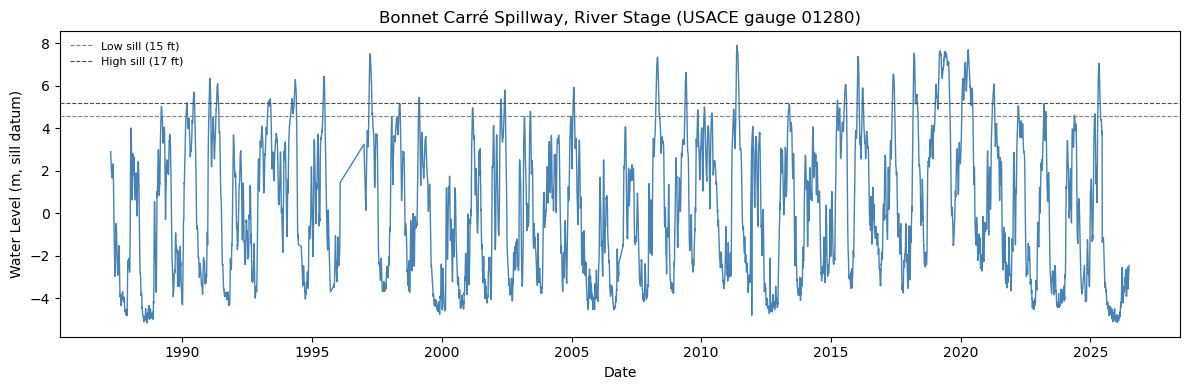

In [27]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(
    bcs_wl.loc[bcs_wl['date'].notna() & bcs_wl['waterlevel'].notna(), 'date'],
    bcs_wl.loc[bcs_wl['date'].notna() & bcs_wl['waterlevel'].notna(), 'waterlevel'],
    lw=1.0, color='steelblue'
)
ax.axhline(15 * ft2m, ls='--', lw=0.8, color='0.5', label='Low sill (15 ft)')
ax.axhline(17 * ft2m, ls='--', lw=0.8, color='0.3', label='High sill (17 ft)')
ax.set_title(f'Bonnet Carré Spillway, River Stage (USACE gauge 01280)')
ax.set_xlabel('Date')
ax.set_ylabel('Water Level (m, sill datum)')
ax.legend(loc='upper left', frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

### 3. Non-operational leakage model

When the spillway is closed, river water seeps through the small gaps between the timber "needles" that fill each bay. This is modeled with the broad-crested weir / slot-flow equation (Chow, 1959; McCorquodale, 2009):

$$Q(t) = f \, L \, C_d \, \sqrt{2g} \, H(t)^{3/2}$$

| Symbol | Meaning | Source / value |
|---|---|---|
| $Q$ | Leakage discharge (m³/s) | computed |
| $L$ | Effective crest length (m) — sum of bay widths only, piers excluded | 2,135 m (350 bays × 20 ft); checked vs. Google Earth total structure length (~2,345 m) minus ~210 m of pier width |
| $f$ | Fraction of $L$ open for leakage (the needle gaps) | derived from geometry below (~4%); independently matches the ~4% fit from the 2008 field observation |
| $C_d$ | Discharge coefficient: $C_d = 0.385 + 0.0025\,(H/P)$ | McCorquodale (2009) |
| $g$ | Gravitational acceleration | 9.81 m/s² |
| $H$ | Head above the weir crest (m) $= \text{water level} - P$ | from datum-corrected stage |
| $P$ | Sill (weir crest) elevation | two values (see below) |

**Two sill elevations** (McCorquodale, 2009): $H$, $C_d$, and $Q$ are computed separately per group and summed:

| Group | Bays | Sill $P$ | Crest length $L$ | Needle length |
|---|---|---|---|---|
| Low sill | 174 | 15 ft (4.572 m) | 1,060 m | 10 ft |
| High sill | 176 | 17 ft (5.182 m) | 1,075 m | 12 ft |

**Leakage fraction $f$:** each bay holds 20 needles side-by-side (8"×12"), giving **21 gaps per bay** (gaps are *between* the 20 needles and sides). Each ~0.5" gap runs the full submerged needle height, behaving as a narrow vertical slot:

$$f = \frac{\text{bays} \times 21 \times \text{gap width}}{L}$$


### 3a. Constants

Define fixed physical constants and spillway geometry used by the leakage model.

In [28]:
# --- Constants ------------------------------------------------------------
g = 9.81                              # gravity (m/s^2)
sqrt2g = np.sqrt(2 * g)

needles_per_bay = 20
gaps_per_bay = needles_per_bay + 1    # 21 gaps between 20 needles and both bay sides
gap_in = 0.5                          # nominal gap width (inches)
gap_m = gap_in * 0.0254               # inches to meters

sill_groups = {
    'low':  {'bays': 174, 'P_ft': 15, 'L': 1060, 'needle_ft': 10},
    'high': {'bays': 176, 'P_ft': 17, 'L': 1075, 'needle_ft': 12},
}
L = sum(s['L'] for s in sill_groups.values())   # 2135 m total (bay widths only; piers excluded)

### 3b. Compute

Compute non-operational leakage by sill group and sum the group contributions into Q_leak_model.

In [29]:
# --- Compute ------------------------------------------------------------
bcs_wl['Q_leak_model'] = 0.0
group_summary = []

for name, s in sill_groups.items():
    P = s['P_ft'] * ft2m              # sill elevation (m)
    H_ceiling = s['needle_ft'] * ft2m # above this = overtopping, not leakage

    H = (bcs_wl['waterlevel'] - P).clip(lower=0, upper=H_ceiling)
    Cd = 0.385 + 0.0025 * (H / P)     # McCorquodale (2009)
    f = (s['bays'] * gaps_per_bay * gap_m) / s['L']

    Q_group = f * s['L'] * Cd * sqrt2g * H ** 1.5
    bcs_wl['Q_leak_model'] += Q_group

    bcs_wl[f'H_{name}'] = H
    group_summary.append(
        f"  {name:>4} sill (P={s['P_ft']}ft, {s['bays']} bays, needle={s['needle_ft']}ft): "
        f"H max={H.max():.3f} m, Q max={Q_group.max():.1f} m^3/s"
    )

### 3c. Operational

Load recorded USACE opening flows, align them to calendar dates, and override modeled leakage on operational days.

In [30]:
# --- Operational --------------------------------------------------------
usace_file = PROJECT_ROOT / "data" / "external" / "Bonnet_Carre_ALL_Weeks_USACE.XLSX"
usace_df = pd.read_excel(usace_file)
usace_df['date'] = pd.to_datetime(usace_df['date'], errors='coerce')
year_cols = [c for c in usace_df.columns if c.startswith('year')]

# Wide to long: one row per (template-day, event-column).
usace_long = usace_df.melt(
    id_vars='date',
    value_vars=year_cols,
    var_name='year_col',
    value_name='usace_diversion_m3s'
)
usace_long['usace_diversion_m3s'] = pd.to_numeric(usace_long['usace_diversion_m3s'], errors='coerce')
usace_long = usace_long[usace_long['usace_diversion_m3s'] > 0].copy()

# Pull out 4-digit year from labels like year2019a / year2019b.
usace_long['year'] = usace_long['year_col'].str.extract(r'(\d{4})').astype(float)
usace_long = usace_long.dropna(subset=['date', 'year'])
usace_long['year'] = usace_long['year'].astype(int)

# Map template day-of-year to actual event-year dates.
usace_long['doy'] = usace_long['date'].dt.dayofyear
year_start = pd.to_datetime(usace_long['year'].astype(str) + '-01-01', errors='coerce')
usace_long['date_actual'] = year_start + pd.to_timedelta(usace_long['doy'] - 1, unit='D')
usace_long = usace_long[usace_long['date_actual'].dt.year == usace_long['year']]

# If duplicate event columns map to one date, keep max.
usace_by_date = (
    usace_long.groupby('date_actual', as_index=False)['usace_diversion_m3s']
    .max()
    .rename(columns={'date_actual': 'date'})
)

# Merge operational discharge and build final combined discharge.
bcs_wl = bcs_wl.drop(columns=['usace_diversion_m3s'], errors='ignore')
bcs_wl = bcs_wl.merge(usace_by_date, on='date', how='left')

operational_mask = bcs_wl['usace_diversion_m3s'].fillna(0) > 0
bcs_wl['discharge_final'] = bcs_wl['Q_leak_model']
bcs_wl.loc[operational_mask, 'discharge_final'] = bcs_wl.loc[operational_mask, 'usace_diversion_m3s']
bcs_wl['regime'] = np.where(operational_mask, 'operational', 'leakage')

### 3d. Stats

Print a concise audit of constants, per-sill diagnostics, and discharge ranges.

In [31]:
# --- Stats --------------------------------------------------------------
print('--- Leakage Equation Variable Audit ---')
print(f'L (total crest length, m): {L}')
print(f'g (gravity, m/s^2): {g}')
print(f'gaps per bay: {gaps_per_bay}  (needles_per_bay + 1)')
print(f'gap width (m): {gap_m:.6f}')
print('Summary by Sill Height:')
for line in group_summary:
    print(line)
print(f'Modeled leakage min/max (m^3/s): {bcs_wl["Q_leak_model"].min():.2f} / {bcs_wl["Q_leak_model"].max():.2f}')
print(f'USACE operational days (count): {int(operational_mask.sum())}')
print(f'Final discharge min/max (m^3/s): {bcs_wl["discharge_final"].min():.2f} / {bcs_wl["discharge_final"].max():.2f}')

--- Leakage Equation Variable Audit ---
L (total crest length, m): 2135
g (gravity, m/s^2): 9.81
gaps per bay: 21  (needles_per_bay + 1)
gap width (m): 0.012700
Summary by Sill Height:
   low sill (P=15ft, 174 bays, needle=10ft): H max=3.048 m, Q max=422.9 m^3/s
  high sill (P=17ft, 176 bays, needle=12ft): H max=2.716 m, Q max=359.5 m^3/s
Modeled leakage min/max (m^3/s): 0.00 / 782.41
USACE operational days (count): 282
Final discharge min/max (m^3/s): 0.00 / 8946.06


### 3e. Plot

Plot modeled leakage and recorded operational discharge on the same timeline for visual QA.

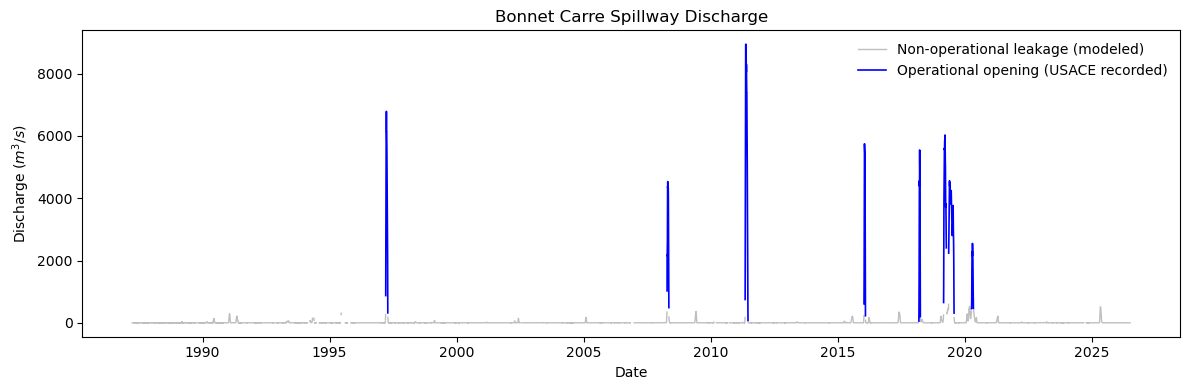

In [37]:
# --- Plot ---------------------------------------------------------------
discharge_plot = bcs_wl.loc[
    bcs_wl['date'].notna(),
    ['date', 'Q_leak_model', 'discharge_final', 'usace_diversion_m3s']
].sort_values('date')
opening_mask = discharge_plot['usace_diversion_m3s'].fillna(0) > 0

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(
    discharge_plot['date'],
    discharge_plot['Q_leak_model'].where(~opening_mask),
    lw=1.0,
    color='0.75',
    label='Non-operational leakage (modeled)'
)
ax.plot(
    discharge_plot['date'],
    discharge_plot['discharge_final'].where(opening_mask),
    lw=1.2,
    color='blue',
    label='Operational opening (USACE recorded)'
)
ax.set_title('Bonnet Carre Spillway Discharge')
ax.set_xlabel('Date')
ax.set_ylabel(f'Discharge ($m^3/s$)')
ax.legend(loc='upper right', frameon=False)
plt.tight_layout()
plt.show()

### 4. Export Final Discharge by Date (2000 → end of record)

Writes `bcs_leakage_discharge_2000_June2026.csv` with one row per day from 2000-01-01 to the last date in the stage record.

This export includes only two columns:
- `date`
- `discharge`

How `discharge` is built:
- Default value is modeled leakage (`Q_leak_model`).
- If an operational opening exists for that date in `Bonnet_Carre_ALL_Weeks_USACE.XLSX`, the recorded USACE discharge replaces the leakage value.

Change `START_YEAR` below to export a different date range.

In [33]:
# --- Export final discharge by date --------------------------------------
START_YEAR = 2000   # change to re-scope the export

export = (
    bcs_wl.loc[bcs_wl['date'].notna(), ['date', 'discharge_final']]
    .rename(columns={'discharge_final': 'discharge'})
    .sort_values('date')
)
export = export[export['date'].dt.year >= START_YEAR].copy()

# Round for a tidy file (full precision stays in the DataFrame).
export['discharge'] = export['discharge'].round(3)

out_path = PROJECT_ROOT / "outputs" / "bcs" / 'bcs_leakage_discharge_2000_June2026.csv'
export.to_csv(out_path, index=False)

print(f'Wrote {len(export):,} rows to {out_path}')
print(f"Date range: {export['date'].min().date()} to {export['date'].max().date()}")
print(f"Peak discharge (m^3/s): {export['discharge'].max():.1f}")
export.head()

Wrote 9,643 rows to c:\Users\hydro\Lake_Pontchartrain_Model\outputs\bcs\bcs_leakage_discharge_2000_June2026.csv
Date range: 2000-01-01 to 2026-06-30
Peak discharge (m^3/s): 8946.1


,date,discharge
4329,2000-01-01,0.0
4330,2000-01-02,0.0
4331,2000-01-03,0.0
4332,2000-01-04,0.0
4333,2000-01-05,0.0
